In [68]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential,layers
import zipfile

In [69]:
zip = zipfile.ZipFile("/content/drive/MyDrive/Colab Notebooks/Fruits_Vegetables.zip")

In [70]:
zip.extractall("classdataset")

In [71]:
img_height = 226
img_width = 226

In [101]:
# 1. Load dataset pointing directly to the train folder
training_dataset = tf.keras.utils.image_dataset_from_directory(
    "/content/classdataset/Fruits_Vegetables/train",
    color_mode="rgb",
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(img_height, img_width),
    batch_size=128
)

# Verify that the class names are now actual vegetables
class_names = training_dataset.class_names
print("Classes:", class_names)
# Output should look like: ['apple', 'banana', 'beetroot', 'bell pepper', ...]

Found 2471 files belonging to 36 classes.
Using 1977 files for training.
Classes: ['apple', 'banana', 'beetroot', 'bell pepper', 'cabbage', 'capsicum', 'carrot', 'cauliflower', 'chilli pepper', 'corn', 'cucumber', 'eggplant', 'garlic', 'ginger', 'grapes', 'jalepeno', 'kiwi', 'lemon', 'lettuce', 'mango', 'onion', 'orange', 'paprika', 'pear', 'peas', 'pineapple', 'pomegranate', 'potato', 'raddish', 'soy beans', 'spinach', 'sweetcorn', 'sweetpotato', 'tomato', 'turnip', 'watermelon']


In [102]:
training_dataset.class_names

['apple',
 'banana',
 'beetroot',
 'bell pepper',
 'cabbage',
 'capsicum',
 'carrot',
 'cauliflower',
 'chilli pepper',
 'corn',
 'cucumber',
 'eggplant',
 'garlic',
 'ginger',
 'grapes',
 'jalepeno',
 'kiwi',
 'lemon',
 'lettuce',
 'mango',
 'onion',
 'orange',
 'paprika',
 'pear',
 'peas',
 'pineapple',
 'pomegranate',
 'potato',
 'raddish',
 'soy beans',
 'spinach',
 'sweetcorn',
 'sweetpotato',
 'tomato',
 'turnip',
 'watermelon']

In [103]:
import matplotlib.pyplot as plt
from PIL import Image
import cv2

In [104]:
cv2.imread("/content/classdataset/Fruits_Vegetables/train/apple")

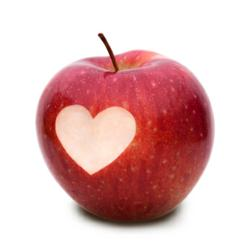

In [105]:
Image.open("/content/classdataset/Fruits_Vegetables/train/apple/Image_16.jpg")

In [106]:
import os

num_skipped = 0

main_folder = "/content/classdataset/Fruits_Vegetables"

for split_name in os.listdir(main_folder):

    split_path = os.path.join(main_folder, split_name)

    # Make sure train/test/validation is a folder
    if not os.path.isdir(split_path):
        continue

    for class_name in os.listdir(split_path):

        class_path = os.path.join(split_path, class_name)

        # Make sure apple/pomegranate/etc. is a folder
        if not os.path.isdir(class_path):
            continue

        for fname in os.listdir(class_path):

            fpath = os.path.join(class_path, fname)

            # Make sure this is actually a file
            if not os.path.isfile(fpath):
                continue

            try:
                with open(fpath, "rb") as fobj:
                    is_jfif = b"JFIF" in fobj.peek(10)

            except Exception:
                is_jfif = False

            if not is_jfif:
                num_skipped += 1
                os.remove(fpath)

print(f"Deleted {num_skipped} corrupted images.")

Deleted 0 corrupted images.


In [107]:
model = Sequential([
    layers.Input(shape=(img_height,img_height,3)),
    layers.Conv2D(16,(3),padding="same",activation="relu"),
    layers.MaxPool2D(2),
    layers.Conv2D(32,(3),padding="same",activation="relu"),
    layers.MaxPool2D(2),
    layers.Conv2D(64,(3),padding="same",activation="relu"),
    layers.Conv2D(128,(3),padding="same",activation="relu"),
    layers.MaxPool2D(2),
    layers.Flatten(),
    layers.Dense(128,activation="relu"),
    layers.Dense(1,activation="sigmoid"),
])

In [108]:
model.compile(optimizer="rmsprop",loss="binary_crossentropy",metrics=["accuracy"])

In [109]:
model.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_32 (Conv2D)              │ (None, 226, 226, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_24 (MaxPooling2D) │ (None, 113, 113, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_33 (Conv2D)              │ (None, 113, 113, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_25 (MaxPooling2D) │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_35 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_26 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,942,753 (49.37 MB)

 Trainable params: 12,942,753 (49.37 MB)

 Non-trainable params: 0 (0.00 B)

In [110]:
history = model.fit(training_dataset,epochs=5,batch_size=128)

Epoch 1/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 41s 2s/step - accuracy: 0.0243 - loss: -20024844288.0000
Epoch 2/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 28s 2s/step - accuracy: 0.0243 - loss: -1120982401024.0000
Epoch 3/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 29s 2s/step - accuracy: 0.0243 - loss: -9046906109952.0000
Epoch 4/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 29s 2s/step - accuracy: 0.0243 - loss: -35599461384192.0000
Epoch 5/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 41s 2s/step - accuracy: 0.0243 - loss: -101617567268864.0000


In [112]:
import numpy as np
img = Image.open("/content/apple.jpg")
img = np.array(img.resize((img_height,img_width)))
img = tf.expand_dims(img,0)
pred = model.predict(img)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step


In [113]:
import numpy as np

# 1. Get ordered class names from training dataset
class_names = training_dataset.class_names

# 2. Preprocess image
img = Image.open("/content/apple.jpg")
img = np.array(img.resize((img_height, img_width)))
img = tf.expand_dims(img, 0)

# 3. Predict probabilities/logits
pred = model.predict(img)

# 4. Get index with highest score
predicted_class_index = np.argmax(pred[0])
predicted_class = class_names[predicted_class_index]
confidence = tf.nn.softmax(pred[0])[predicted_class_index].numpy() * 100

print(f"Predicted Class: {predicted_class}")
print(f"Confidence: {confidence:.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
Predicted Class: apple
Confidence: 100.00%
